# iCare -> Goldmann IOP: linear regression experiments

Predicting `applanation_iop` (Goldmann, the clinical reference) from
`icare_iop` (rebound tonometer) and `cct` (central corneal thickness).

Put `train.csv`, `validation.csv`, `test.csv` in the same folder as this
notebook. Fit on train, compare on validation, touch test only at the end.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

TARGET = "applanation_iop"

In [2]:
def load(path):
    df = pd.read_csv(path, parse_dates=["date"])
    df["eye"] = df["euid"].str[0]           # L or R
    df["patient_id"] = df["euid"].str[1:]
    return df

train = load("train.csv")
val   = load("validation.csv")
test  = load("test.csv")

y_tr, y_va, y_te = train[TARGET], val[TARGET], test[TARGET]

print({k: len(v) for k, v in [("train", train), ("val", val), ("test", test)]})
train.head()

{'train': 4648, 'val': 1001, 'test': 990}


,date,euid,icare_iop,cct,applanation_iop,eye,patient_id
0,2026-03-02,L00220,18.0,488.0,17.0,L,00220
1,2026-03-02,L00228,19.0,533.0,16.0,L,00228
2,2026-03-02,L00241,20.0,550.0,18.0,L,00241
3,2026-03-02,L00254,21.0,560.0,22.0,L,00254
4,2026-03-02,L00279,17.0,504.0,14.0,L,00279


## 2. What the data looks like

In [3]:
for name, df in [("train", train), ("validation", val), ("test", test)]:
    print(f"\n--- {name}: {len(df)} eyes, {df.patient_id.nunique()} patients")
    print(df[["icare_iop", "cct", TARGET]].describe().loc[["mean","std","min","max"]].round(2))


--- train: 4648 eyes, 2536 patients
      icare_iop     cct  applanation_iop
mean      18.00  536.91             18.7
std        7.06   24.88              7.2
min        4.00  480.00              2.0
max       70.00  580.00             70.0

--- validation: 1001 eyes, 544 patients
      icare_iop     cct  applanation_iop
mean      17.99  537.37            18.79
std        6.83   24.31             7.03
min        5.00  480.00             6.00
max       70.00  580.00            60.00

--- test: 990 eyes, 544 patients
      icare_iop     cct  applanation_iop
mean      17.95  537.50            19.07
std        7.48   24.42             7.68
min        3.00  480.00             3.00
max       72.00  580.00            68.00


In [4]:
# Splits are only trustworthy if no patient straddles them (both eyes of one
# person are highly correlated, so a shared patient leaks).
tr_p, va_p, te_p = set(train.patient_id), set(val.patient_id), set(test.patient_id)
print("train & val :", len(tr_p & va_p))
print("train & test:", len(tr_p & te_p))
print("val & test  :", len(va_p & te_p))

train & val : 0
train & test: 0
val & test  : 0


In [5]:
train[["icare_iop", "cct", TARGET]].corr().round(3)

,icare_iop,cct,applanation_iop
icare_iop,1.000,0.132,0.834
cct,0.132,1.000,0.075
applanation_iop,0.834,0.075,1.000


`icare_iop` correlates ~0.83 with the target. `cct` correlates ~0.08, which is
the first sign that corneal thickness is not pulling weight in this dataset
even though correcting for it is the clinical motivation for measuring it.

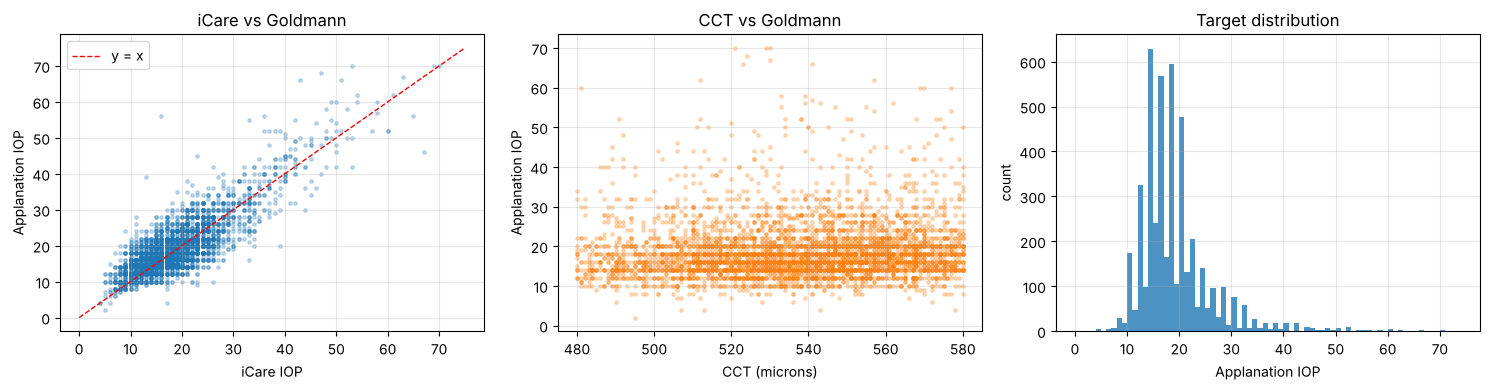

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].scatter(train.icare_iop, train[TARGET], s=6, alpha=0.25)
lims = [0, train[TARGET].max() + 5]
ax[0].plot(lims, lims, "r--", lw=1, label="y = x")
ax[0].set(xlabel="iCare IOP", ylabel="Applanation IOP", title="iCare vs Goldmann")
ax[0].legend()

ax[1].scatter(train.cct, train[TARGET], s=6, alpha=0.25, color="tab:orange")
ax[1].set(xlabel="CCT (microns)", ylabel="Applanation IOP", title="CCT vs Goldmann")

ax[2].hist(train[TARGET], bins=range(0, 75), alpha=0.8)
ax[2].set(xlabel="Applanation IOP", ylabel="count", title="Target distribution")
plt.tight_layout()

In [7]:
# The target lives on a 2 mmHg grid: Goldmann is read off a dial in even steps.
# This matters for how predictions should be post-processed.
print("even-valued share, applanation:", round((train[TARGET] % 2 == 0).mean(), 3))
print("even-valued share, icare      :", round((train.icare_iop % 2 == 0).mean(), 3))

even-valued share, applanation: 0.782
even-valued share, icare      : 0.51


## 3. Features and metrics

In [8]:
def f_icare(df):
    return df[["icare_iop"]].to_numpy()

def f_icare_cct(df):
    return df[["icare_iop", "cct"]].to_numpy()

def f_icare_cct_eye(df):
    X = df[["icare_iop", "cct"]].copy()
    X["is_right"] = (df.eye == "R").astype(int)
    return X.to_numpy()

def f_poly(df):
    ic, cc = df.icare_iop.to_numpy(), df.cct.to_numpy()
    ic_c, cc_c = ic - 18.0, cc - 540.0      # fixed centering so splits match
    return np.column_stack([ic, cc, ic_c**2, cc_c**2, ic_c * cc_c])

MODELS = {
    "M1 icare only":        (f_icare,         ["icare"]),
    "M2 icare+cct":         (f_icare_cct,     ["icare", "cct"]),
    "M3 icare+cct+eye":     (f_icare_cct_eye, ["icare", "cct", "is_right"]),
    "M4 quad+interaction":  (f_poly,          ["icare", "cct", "icare_c^2", "cct_c^2", "icare_c*cct_c"]),
}

In [9]:
def evaluate(y_true, y_pred):
    e = np.asarray(y_pred) - np.asarray(y_true)
    return {
        "MAE":  mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2":   r2_score(y_true, y_pred),
        "bias": e.mean(),
        "<=2mmHg%": (np.abs(e) <= 2).mean() * 100,
        "<=3mmHg%": (np.abs(e) <= 3).mean() * 100,
    }

def table(rows):
    return pd.DataFrame(rows).T.round(3)

## 4. Baselines before any model

In [10]:
# If a model cannot beat "just report the iCare number", it has earned nothing.
table({
    "predict icare as-is": evaluate(y_va, val.icare_iop),
    "predict train mean":  evaluate(y_va, np.full(len(y_va), y_tr.mean())),
})

,MAE,RMSE,R2,bias,<=2mmHg%,<=3mmHg%
predict icare as-is,2.996,4.258,0.633,-0.800,54.945,68.731
predict train mean,4.844,7.031,-0.000,-0.091,28.472,44.755


## 5. Model comparison on validation

In [11]:
fitted, rows = {}, {}
for label, (featf, names) in MODELS.items():
    m = LinearRegression().fit(featf(train), y_tr)
    fitted[label] = (m, featf, names)
    rows[label] = evaluate(y_va, m.predict(featf(val)))

rows["(baseline) icare as-is"] = evaluate(y_va, val.icare_iop)
table(rows)

,MAE,RMSE,R2,bias,<=2mmHg%,<=3mmHg%
M1 icare only,2.883,4.043,0.669,-0.105,48.452,65.634
M2 icare+cct,2.892,4.042,0.669,-0.110,47.852,64.535
M3 icare+cct+eye,2.890,4.039,0.670,-0.109,48.252,65.235
M4 quad+interaction,2.832,4.012,0.674,-0.132,48.851,66.034
(baseline) icare as-is,2.996,4.258,0.633,-0.800,54.945,68.731


Read the spread before picking a winner. If the models sit within a few
hundredths of a mmHg of each other, the ranking is noise and the simplest
model is the one to report.

In [12]:
# Are the added terms actually significant? statsmodels gives p-values that
# sklearn does not. Watch the cct row in particular.
import statsmodels.api as sm

X = sm.add_constant(train[["icare_iop", "cct"]])
print(sm.OLS(y_tr, X).fit().summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          8.7911      1.256      7.000      0.000       6.329      11.253
icare_iop      0.8549      0.008    102.943      0.000       0.839       0.871
cct           -0.0102      0.002     -4.336      0.000      -0.015      -0.006


Note the trap here. `cct` comes out statistically significant (p < 0.001),
because with 4648 rows almost anything will. But the coefficient is about
-0.01 mmHg per micron, so a 100 micron swing in corneal thickness, which is
most of the range in this data, moves the prediction by only 1 mmHg. That is
significance without practical effect, and it is exactly why section 5 shows
no predictive gain from adding the column. Report both facts together or the
p-value alone will mislead.

## 6. Selected model, scored on test once

In [13]:
best = min(MODELS, key=lambda L: mean_absolute_error(y_va, fitted[L][0].predict(fitted[L][1](val))))
model, featf, names = fitted[best]
print("selected:", best)
print("intercept", round(model.intercept_, 4))
for n, c in zip(names, model.coef_):
    print(f"  {n:<16}{c:>12.5f}")

selected: M4 quad+interaction
intercept 8.1166
  icare                0.75387
  cct                 -0.00631
  icare_c^2            0.00738
  cct_c^2              0.00008
  icare_c*cct_c       -0.00096


In [14]:
pred_te = model.predict(featf(test))

table({
    "train":      evaluate(y_tr, model.predict(featf(train))),
    "validation": evaluate(y_va, model.predict(featf(val))),
    "TEST":       evaluate(y_te, pred_te),
})

,MAE,RMSE,R2,bias,<=2mmHg%,<=3mmHg%
train,2.839,3.874,0.710,-0.000,46.450,64.651
validation,2.832,4.012,0.674,-0.132,48.851,66.034
TEST,2.909,3.992,0.729,-0.375,46.768,63.434


### Snapping to the measurement grid

Continuous predictions never land on the 2 mmHg grid the target is recorded
on, which is why the raw model can have a better MAE but a worse "within
2 mmHg" rate than echoing the iCare reading. Rounding costs nothing and
recovers that agreement.

In [15]:
table({
    "raw":                evaluate(y_te, pred_te),
    "rounded to integer": evaluate(y_te, np.round(pred_te)),
    "rounded to even":    evaluate(y_te, np.round(pred_te / 2) * 2),
})

,MAE,RMSE,R2,bias,<=2mmHg%,<=3mmHg%
raw,2.909,3.992,0.729,-0.375,46.768,63.434
rounded to integer,2.897,3.996,0.729,-0.386,54.747,70.808
rounded to even,2.867,4.017,0.726,-0.444,60.404,66.768


## 7. Where the model fails

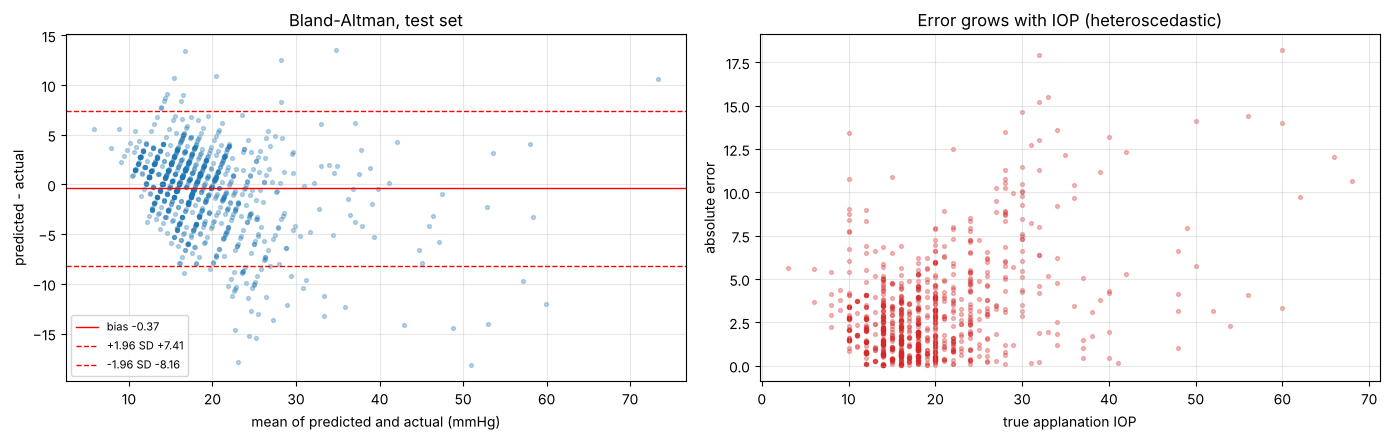

In [16]:
err = pred_te - y_te.to_numpy()
mean_iop = (pred_te + y_te.to_numpy()) / 2
bias, sd = err.mean(), err.std()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

ax[0].scatter(mean_iop, err, s=8, alpha=0.3)
for v, ls, lab in [(bias, "-", f"bias {bias:+.2f}"),
                   (bias + 1.96*sd, "--", f"+1.96 SD {bias+1.96*sd:+.2f}"),
                   (bias - 1.96*sd, "--", f"-1.96 SD {bias-1.96*sd:+.2f}")]:
    ax[0].axhline(v, color="r", ls=ls, lw=1, label=lab)
ax[0].set(xlabel="mean of predicted and actual (mmHg)", ylabel="predicted - actual",
          title="Bland-Altman, test set")
ax[0].legend(fontsize=8)

ax[1].scatter(y_te, np.abs(err), s=8, alpha=0.3, color="tab:red")
ax[1].set(xlabel="true applanation IOP", ylabel="absolute error",
          title="Error grows with IOP (heteroscedastic)")
plt.tight_layout()

In [17]:
bands = pd.cut(y_te, [0, 10, 15, 21, 30, 100], labels=["<=10","11-15","16-21","22-30",">30"])
(pd.DataFrame({"abs_err": np.abs(err), "band": bands})
   .groupby("band", observed=True)
   .agg(n=("abs_err", "size"), MAE=("abs_err", "mean")).round(2))

,n,MAE
band,,
<=10,59,3.77
11-15,256,2.16
16-21,435,2.12
22-30,179,4.30
>30,61,6.75


Most eyes sit in the 11 to 21 band where the model does well. Accuracy falls
apart above 22 mmHg, which is the range that actually matters clinically for
glaucoma. Any honest writeup should say so.

## 8. Your scratch space

Ideas worth trying from here:

- `np.log` the target, refit, and see whether the fan-shaped residuals flatten
- fit `sklearn.linear_model.HuberRegressor` so the high-IOP outliers stop
  dragging the line
- add `cct` as a deviation from 540 microns interacted with icare, which is the
  form the clinical correction nomograms actually use
- `RandomForestRegressor` or `GradientBoostingRegressor` as a non-linear
  reference point, mainly to see if the high-IOP band improves
- group eyes by `patient_id` and check whether errors are correlated within
  patient, which would mean your effective sample size is smaller than 4648

In [18]:
# scratch